# JSONBench: larger EC2 server results

Analysis of the native **c8i.4xlarge (16 vCPU / 32 GiB)** experiment. Both databases had a **12 GiB service cap**; MongoDB cache 6 GiB, Couchbase Data 4 GiB / Index 2 GiB. The runner shared the host. This is one host, three sequential workload repetitions per configuration—not three independent machines.

**Recommended paper layout:** two metric rows × three scale-factor columns, client count on x. Keep backend, SF and clients separate; summarise only repetitions. Companion failure-rate panels are essential. Companion views below show successful query counts and failure heatmaps.

This notebook reads the downloaded artifacts without changing them. All outputs go to `analysis/ec2-large-figures`. Run from the repository or notebooks directory. Requires pandas, numpy, matplotlib and a Jupyter Python kernel. The data download is not included in Git.

**Caveats:** Couchbase experienced query-engine OOM kills. “Complete” means the benchmark recorded a completed run, not uninterrupted database operation. Successful-query latency excludes failed queries and is subject to survivorship bias. Mixed-workload means also reflect the realised query mix; inspect the per-query table before attributing changes to individual-query performance.

In [1]:
from pathlib import Path
import json, re
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "jsonbench/matrix.py").exists())
DATA = ROOT / "analysis/ec2-large-results/paper-v1"
OUT = ROOT / "analysis/ec2-large-figures"
OUT.mkdir(parents=True, exist_ok=True)
assert DATA.exists(), f"Missing downloaded results: {DATA}"
plt.rcParams.update({"figure.dpi": 200, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42, "savefig.bbox": "tight"})
COLORS = {"mongodb": "#2166ac", "couchbase": "#b35806"}
LABELS = {"mongodb": "MongoDB", "couchbase": "Couchbase"}
SCALES = [10, 100, 200]
CLIENTS = [2, 4, 8, 16, 32, 64]
def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=200)
    fig.savefig(OUT / f"{name}.pdf")
    plt.show()


## Metric definitions and integrity checks

- **Throughput:** successful completions inside the measurement interval divided by its 180 seconds. This includes warm-up-started queries finishing during measurement and excludes late completions.
- **Latency:** mean duration of successful attempts **started during measurement**, including drained completions. It is not reciprocal throughput.
- **Failure rate:** errors + timeouts divided by completed attempts **started during measurement**, including drain. Timeout and error classifications are retained unchanged.
- Lines are unweighted means of the three run-level metrics; shading is their **minimum–maximum range**, not a confidence interval. Dots show individual repetitions. No pooling across SF or client count.
- OOM correlation uses the full attempt interval (including preparation/verification), not a claimed exact timed-measurement overlap. Kernel timestamps have second resolution. The run metadata does not save the wall-clock workload origin.


In [2]:
plan = json.loads((DATA / "plan.json").read_text())
state = json.loads((DATA / "state.json").read_text())
# One canonical kernel snapshot; do not concatenate overlapping snapshots and double-count kills.
kernel = (DATA / "kernel-20261110T2215.log").read_text()
oom_times = []
for line in kernel.splitlines():
    if "Killed process" in line and "(cbq-engine)" in line:
        stamp = datetime.strptime("2026 " + line[:15], "%Y %b %d %H:%M:%S").replace(tzinfo=timezone.utc)
        oom_times.append(stamp.timestamp())
rows, query_rows, audit = [], [], []
for cell in plan["cells"]:
    history = state["attempts"].get(cell["id"], [])
    assert history and history[-1]["state"] == "complete", f"Incomplete: {cell['id']}"
    attempt = history[-1]
    # Recorded paths refer to EC2; relocate only the suffix under attempts/.
    relative = attempt["run_path"].split("/attempts/", 1)[1]
    run = DATA / "attempts" / relative
    info = json.loads((run / "info.json").read_text())
    summary = json.loads((run / "summary.json").read_text())
    events = [json.loads(line) for line in (run / "events.jsonl").open()]
    completed = [e for e in events if e["event"] == "completed"]
    start, end = info["warmup_seconds"], info["warmup_seconds"] + info["measurement_seconds"]
    admitted = [e for e in completed if start <= e["start_seconds"] < end]
    starts = {e["attempt_id"] for e in events if e["event"] == "started"}
    finishes = {e["attempt_id"] for e in completed}
    assert starts == finishes and len(finishes) == len(completed), cell["id"]
    success = [e for e in admitted if e["status"] == "success"]
    throughput = sum(e["status"] == "success" and start <= e["finish_seconds"] < end for e in completed) / info["measurement_seconds"]
    assert np.isclose(throughput, summary["successful_completion_throughput_qps"])
    for status, key in [("success", "measurement_successes"), ("timeout", "measurement_timeouts"), ("error", "measurement_errors")]:
        assert sum(e["status"] == status for e in admitted) == summary[key]
    latency = np.mean([e["time"] for e in success]) if success else np.nan
    assert (not success and summary["measurement_success_mean_seconds"] is None) or np.isclose(latency, summary["measurement_success_mean_seconds"])
    kills = sum(attempt["started_at"] <= t <= attempt["finished_at"] for t in oom_times)
    row = dict(cell=cell["id"], backend=cell["backend"], sf=cell["scale_factor"],
               clients=cell["workers"], repetition=cell["repetition"], throughput_qps=throughput,
               successful_latency_s=latency, admitted=len(admitted), successes=len(success),
               timeouts=summary["measurement_timeouts"], errors=summary["measurement_errors"],
               oom_kills=kills, oom_affected=kills > 0, attempt_count=len(history))
    row["failure_pct"] = 100 * (row["timeouts"] + row["errors"]) / len(admitted) if admitted else np.nan
    rows.append(row)
    for name in sorted({e["name"] for e in completed}):
        es = [e for e in admitted if e["name"] == name]
        ok = [e["time"] for e in es if e["status"] == "success"]
        query_rows.append({**{k: row[k] for k in ["cell", "backend", "sf", "clients", "repetition", "oom_affected"]},
            "query": name, "attempts": len(es), "successes": len(ok),
            "timeouts": sum(e["status"] == "timeout" for e in es),
            "errors": sum(e["status"] == "error" for e in es),
            "successful_latency_s": np.mean(ok) if ok else np.nan})
    audit.append({"cell": cell["id"], "dataset_hash": info["dataset_manifest_sha256"], "revision": info["revision"]})
runs = pd.DataFrame(rows)
per_query = pd.DataFrame(query_rows)
assert len(runs) == 108
assert runs.groupby(["backend", "sf", "clients"]).size().eq(3).all()
assert len({a["revision"] for a in audit}) == 1
for sf in SCALES:
    assert len({a["dataset_hash"] for a in audit if a["cell"] in set(runs.loc[runs.sf == sf, "cell"])}) == 1
runs.to_csv(OUT / "run_metrics.csv", index=False)
per_query.to_csv(OUT / "per_query_metrics.csv", index=False)
display(runs.groupby("backend").agg(runs=("cell", "size"), timeouts=("timeouts", "sum"),
    errors=("errors", "sum"), oom_affected_runs=("oom_affected", "sum"), attributed_oom_kills=("oom_kills", "sum")))
print(f"Kernel kills: {len(oom_times)}; attributed to attempt intervals: {runs.oom_kills.sum()}")


,runs,timeouts,errors,oom_affected_runs,attributed_oom_kills
backend,,,,,
couchbase,54,1870,6012,12,81
mongodb,54,1000,0,0,0


Kernel kills: 81; attributed to attempt intervals: 81


## Option A — recommended main paper figure

Columns fix scale factor; x varies client count. This makes saturation and latency growth easy to compare without conflating dataset size and concurrency. Both metrics use log y-axes to accommodate orders of magnitude. OOM markers are omitted here and retained in the companion failure diagrams. The LaTeX caption should state that throughput counts successful completions, latency includes successful queries only, and all runs (including OOM-affected runs) are retained. Null latency (no successes) is omitted, not plotted as zero. Always read this alongside the failure panels below.

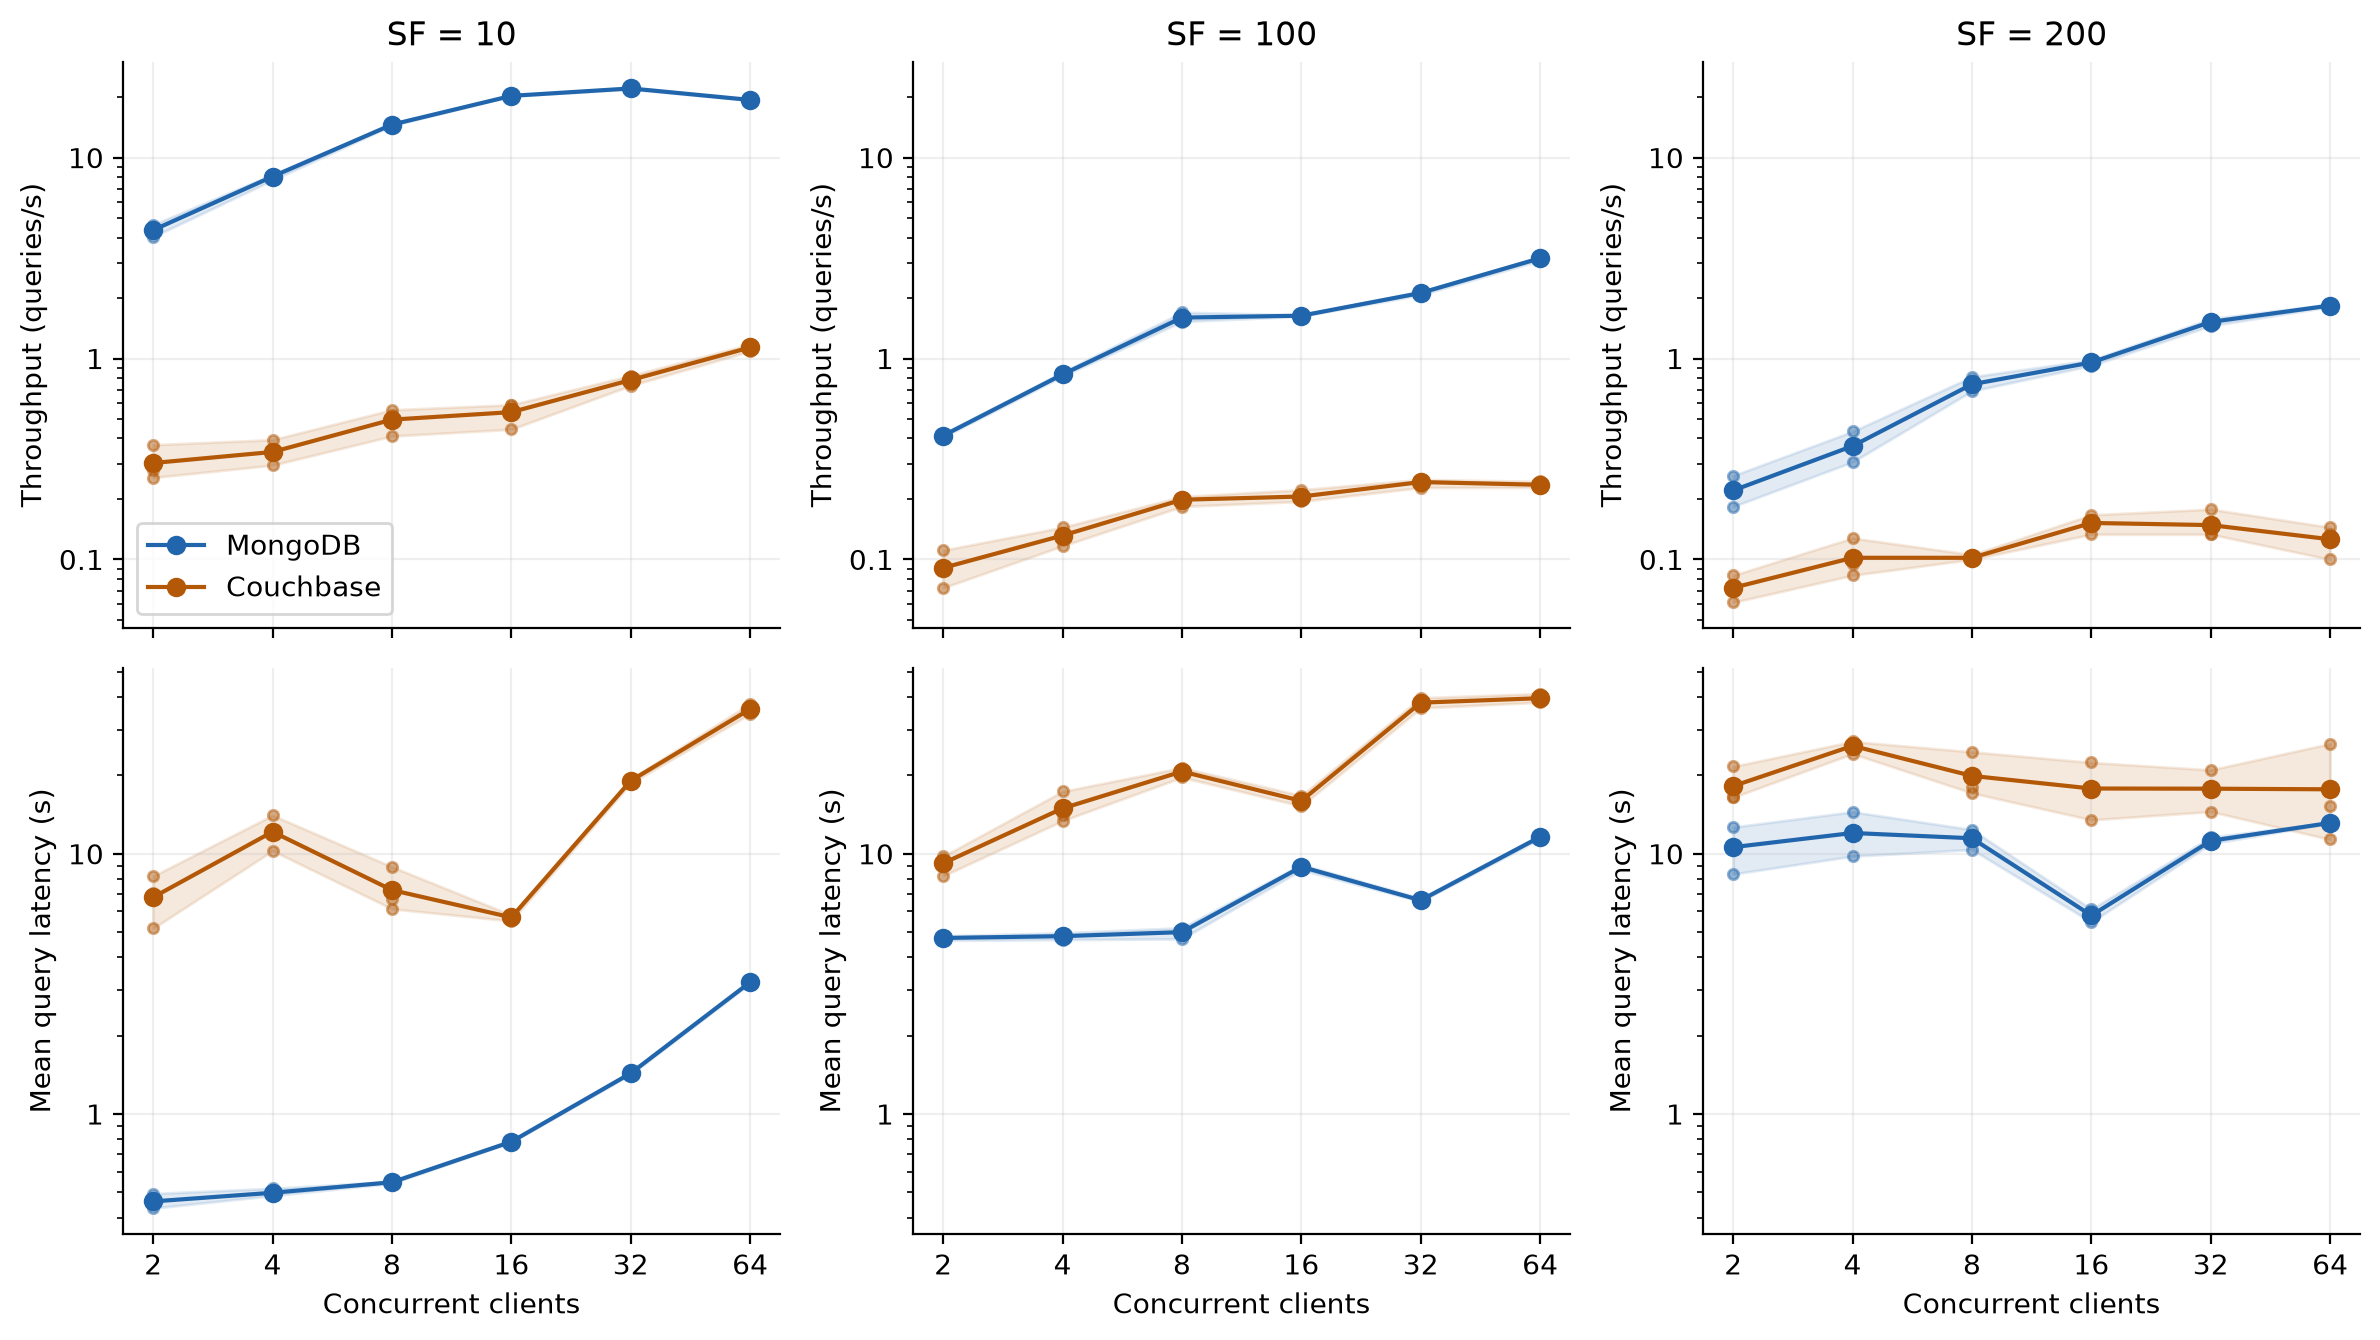

In [3]:
def draw(ax, data, x, metric, mark_oom=True):
    for backend, color in COLORS.items():
        d = data[data.backend == backend]
        g = d.groupby(x)[metric].agg(["mean", "min", "max"])
        ax.plot(g.index, g["mean"], marker="o", color=color, label=LABELS[backend])
        ax.fill_between(g.index.to_numpy(), g["min"].to_numpy(), g["max"].to_numpy(), color=color, alpha=.13)
        ax.scatter(d[x], d[metric], color=color, alpha=.5, s=14)
        bad = d[d.oom_affected]
        if mark_oom:
            ax.scatter(bad[x], bad[metric], color="black", marker="x", s=45, zorder=5)
    ax.grid(alpha=.2)

fig, axes = plt.subplots(2, 3, figsize=(12, 6.8), sharex=True, sharey="row")
for j, sf in enumerate(SCALES):
    for i, metric in enumerate(["throughput_qps", "successful_latency_s"]):
        ax = axes[i, j]; draw(ax, runs[runs.sf == sf], "clients", metric, mark_oom=False)
        ax.set_xscale("log", base=2); ax.set_xticks(CLIENTS, labels=CLIENTS)
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:g}"))
        if i == 0: ax.set_title(f"SF = {sf}")
        else: ax.set_xlabel("Concurrent clients")
for ax in axes[0]:
    ax.set_ylabel("Throughput (queries/s)")
    ax.tick_params(axis="y", labelleft=True)
for ax in axes[1]:
    ax.set_ylabel("Mean query latency (s)")
    ax.tick_params(axis="y", labelleft=True)
axes[0, 0].legend()
fig.tight_layout(); save(fig, "clients_by_scale")


## Failure rates — companion to either performance view

This figure uses the same configuration grouping. The error/timeout split is available in the exported run table. Do not interpret lower successful latency as an improvement when the failure rate grows.

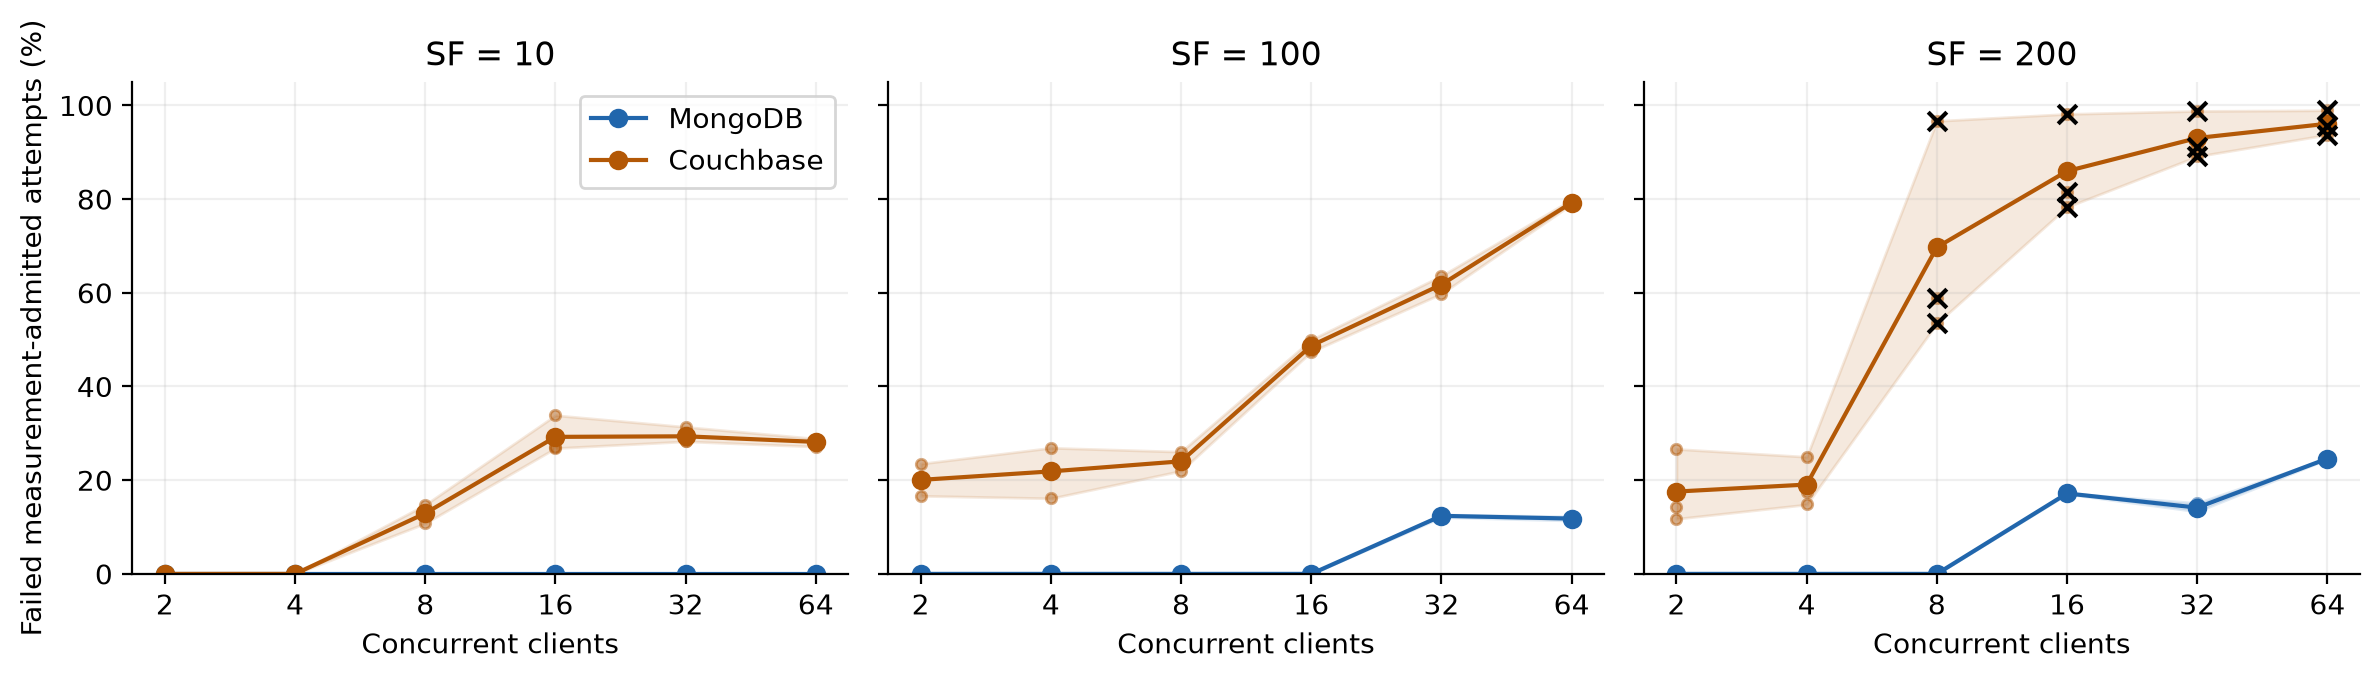

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, sf in zip(axes, SCALES):
    draw(ax, runs[runs.sf == sf], "clients", "failure_pct")
    ax.set_xscale("log", base=2); ax.set_xticks(CLIENTS, labels=CLIENTS)
    ax.set_title(f"SF = {sf}"); ax.set_xlabel("Concurrent clients"); ax.set_ylim(0, 105)
axes[0].set_ylabel("Failed measurement-admitted attempts (%)")
axes[0].legend(); fig.tight_layout(); save(fig, "failures_by_clients")


## Successful query completions by configuration

Three panels fix the scale factor; paired bars compare MongoDB and Couchbase at each client count. Bars show the mean number of successful completions **inside the 180-second measurement window** across three repetitions; error bars show min–max. Errors, timeouts and completions after the window are excluded. Warm-up-started queries finishing within measurement count, matching the throughput definition. Thus this figure is throughput multiplied by 180 seconds, not an independent performance metric.

The panels share a linear y-axis for honest count comparisons across scale factors. Small values remain visible through numeric bar labels. All runs, including OOM-affected runs, are retained; consult the failure diagram.


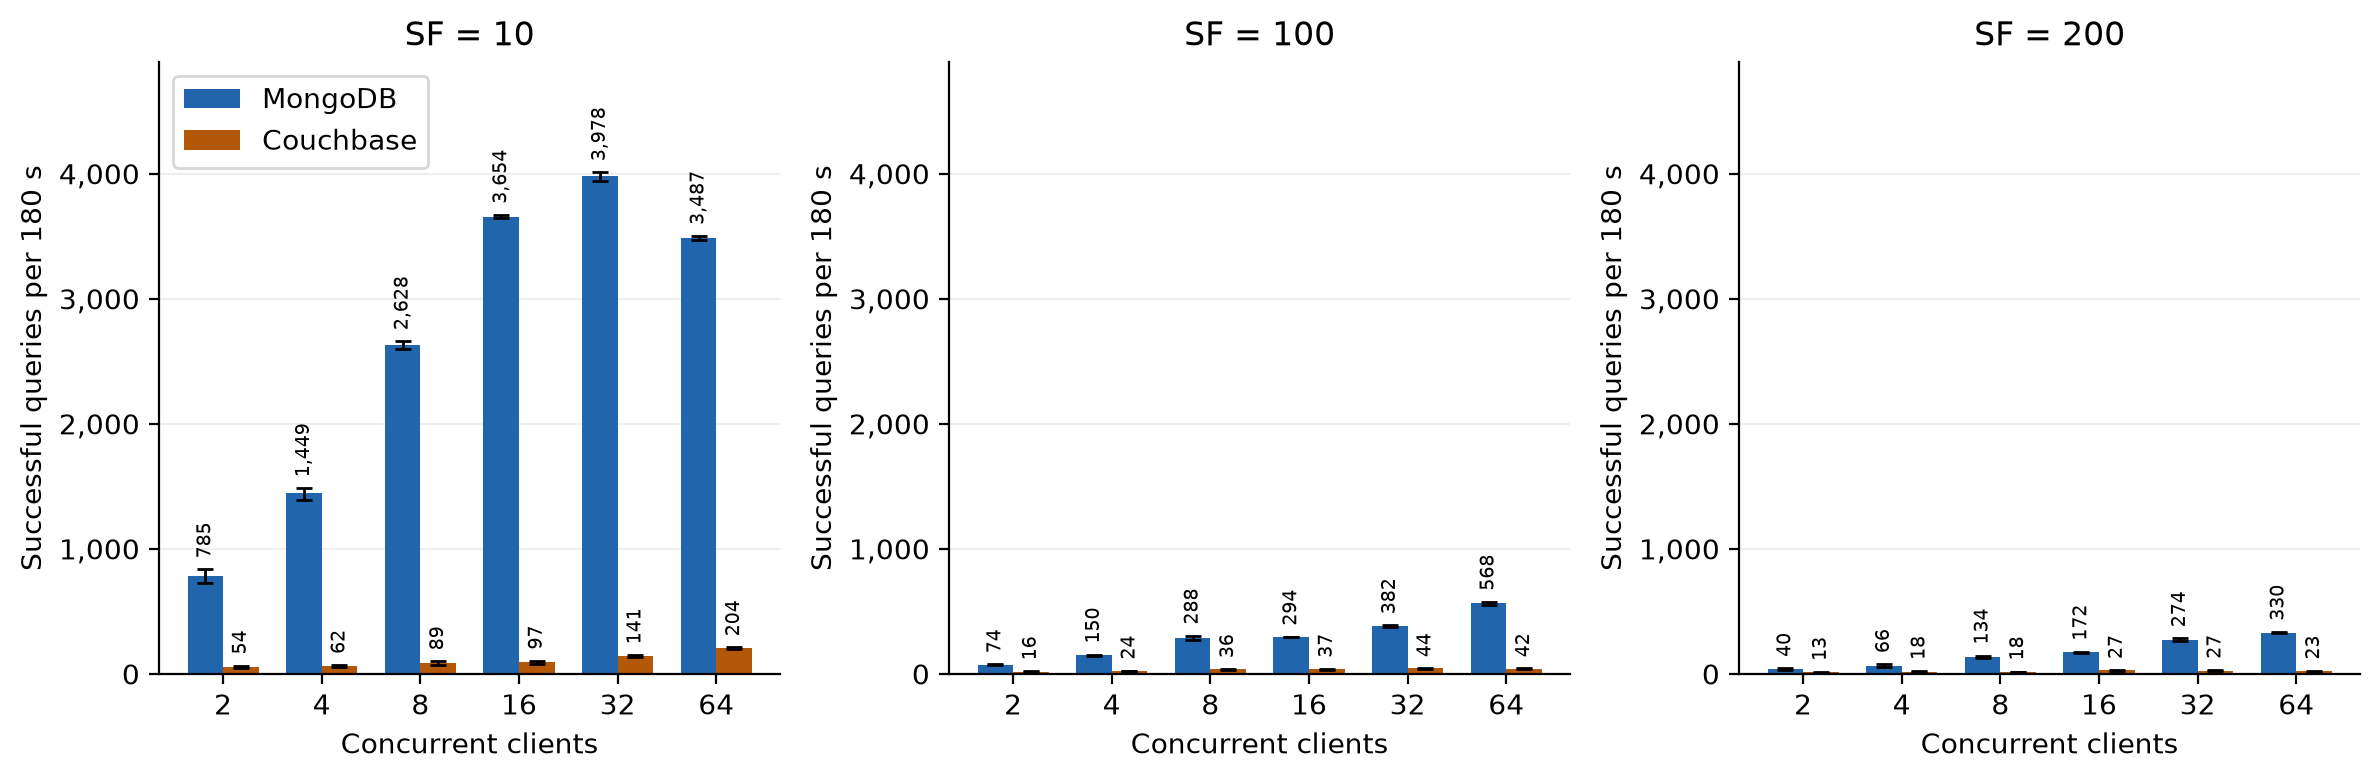

In [5]:
# Count directly from audited throughput and the fixed measurement duration.
measurement_seconds = plan["manifest"]["duration"]
runs["successful_completions_in_window"] = np.rint(runs.throughput_qps * measurement_seconds).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
x = np.arange(len(CLIENTS))
width = .36
for ax, sf in zip(axes, SCALES):
    for j, (backend, color) in enumerate(COLORS.items()):
        d = runs[(runs.sf == sf) & (runs.backend == backend)]
        g = d.groupby("clients")["successful_completions_in_window"].agg(["mean", "min", "max"]).reindex(CLIENTS)
        values = g["mean"].to_numpy()
        positions = x + (j - .5) * width
        ax.bar(positions, values, width, color=color, label=LABELS[backend],
               yerr=np.vstack([values-g["min"].to_numpy(), g["max"].to_numpy()-values]),
               capsize=3, error_kw={"elinewidth": 1})
        for pos, mean, high in zip(positions, values, g["max"]):
            ax.annotate(f"{mean:,.0f}", (pos, high), xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_title(f"SF = {sf}")
    ax.set_xticks(x, labels=CLIENTS)
    ax.set_xlabel("Concurrent clients")
    ax.set_ylabel("Successful queries per 180 s")
    ax.tick_params(axis="y", labelleft=True)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:,.0f}"))
    ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
axes[0].legend()
axes[0].set_ylim(0, runs.successful_completions_in_window.max() * 1.22)
fig.tight_layout(); save(fig, "successful_query_counts")
runs.to_csv(OUT / "run_metrics.csv", index=False)


## Option C — compact two-dimensional failure map

Rows are scale factors; columns are client counts. Each cell shows the mean run-level failure percentage. An asterisk means at least one repetition overlapped an OOM kill. This is a compact companion figure; heatmaps hide repetition variability, so the run table and line plots remain important.

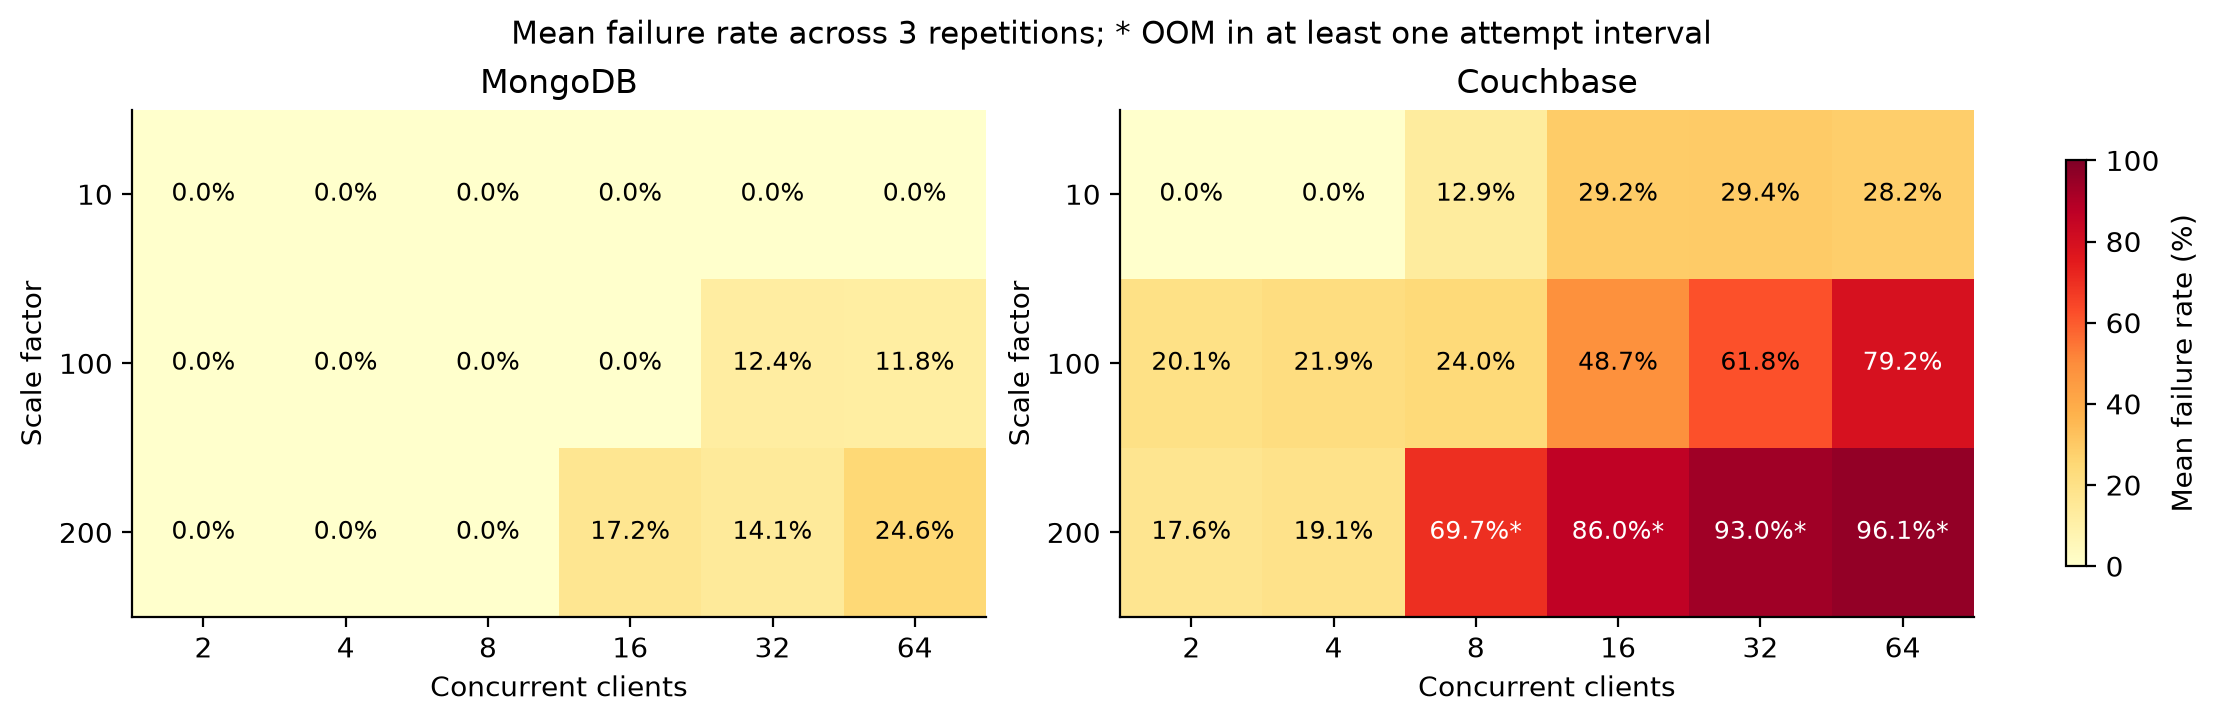

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for ax, backend in zip(axes, COLORS):
    d = runs[runs.backend == backend]
    grid = d.pivot_table(index="sf", columns="clients", values="failure_pct", aggfunc="mean").reindex(index=SCALES, columns=CLIENTS)
    oom = d.pivot_table(index="sf", columns="clients", values="oom_affected", aggfunc="max").reindex(index=SCALES, columns=CLIENTS)
    im = ax.imshow(grid, vmin=0, vmax=100, cmap="YlOrRd", aspect="auto")
    for i in range(len(SCALES)):
        for j in range(len(CLIENTS)):
            v = grid.iloc[i,j]
            ax.text(j,i,f"{v:.1f}%" + ("*" if oom.iloc[i,j] else ""),ha="center",va="center",color="white" if v>65 else "black",fontsize=9)
    ax.set_xticks(range(len(CLIENTS)), labels=CLIENTS); ax.set_yticks(range(len(SCALES)), labels=SCALES)
    ax.set_xlabel("Concurrent clients"); ax.set_ylabel("Scale factor"); ax.set_title(LABELS[backend])
fig.colorbar(im, ax=axes, label="Mean failure rate (%)", shrink=.8)
fig.suptitle("Mean failure rate across 3 repetitions; * OOM in at least one attempt interval", fontsize=11)
save(fig, "failure_heatmaps")


## OOM audit and configuration summary

Do not drop crash-affected runs silently, and do not compute a “clean-only” backend ranking from a different set of configurations. The table below locates the affected attempts. Exact measurement-phase crash attribution needs more precise wall-clock alignment than the saved workload events provide.

The exported per-query table supports follow-up breakdowns by Q1–Q8. Keep those separate from the mixed-workload plots: averaging all queries and averaging per-query means answer different questions. The three repetitions reuse the same generated dataset and change the workload-selection seed.

In [7]:
display(runs.loc[runs.oom_affected, ["cell", "oom_kills", "throughput_qps", "successful_latency_s", "failure_pct"]])
metrics = ["throughput_qps", "successful_latency_s", "failure_pct"]
summary = runs.groupby(["backend", "sf", "clients"])[metrics].agg(["mean", "min", "max"])
summary.to_csv(OUT / "configuration_summary.csv")
display(summary.round(3))
print(f"Figures (PDF + PNG) and derived tables saved to {OUT}")


,cell,oom_kills,throughput_qps,successful_latency_s,failure_pct
92,couchbase-s200-r1-w8,1,0.100000,17.999285,58.974359
93,couchbase-s200-r1-w16,8,0.166667,17.505691,78.333333
94,couchbase-s200-r1-w32,9,0.133333,17.817854,91.176471
95,couchbase-s200-r1-w64,10,0.144444,15.220355,95.560254
96,couchbase-s200-r2-w64,10,0.100000,11.349927,98.964327
97,couchbase-s200-r2-w32,7,0.133333,21.009826,98.817967
98,couchbase-s200-r2-w16,7,0.133333,13.497235,81.415929
99,couchbase-s200-r2-w8,1,0.105556,17.117451,96.695652
104,couchbase-s200-r3-w8,2,0.100000,24.638854,53.488372
105,couchbase-s200-r3-w16,6,0.155556,22.435941,98.185941


throughput_qps                 successful_latency_s  \
                                mean     min     max                 mean   
backend   sf  clients                                                       
couchbase 10  2                0.302   0.256   0.372                6.805   
              4                0.343   0.294   0.394               12.149   
              8                0.496   0.411   0.556                7.254   
              16               0.541   0.444   0.589                5.695   
              32               0.781   0.733   0.822               19.082   
              64               1.135   1.089   1.178               35.973   
          100 2                0.091   0.072   0.111                9.194   
              4                0.131   0.117   0.144               14.941   
              8                0.198   0.183   0.206               20.705   
              16               0.206   0.194   0.222               15.970   
              32               0.243   0.228   0.250               38.078   
              64               0.235   0.228   0.244               39.613   
          200 2                0.072   0.061   0.083               18.203   
              4                0.102   0.083   0.128               25.983   
              8                0.102   0.100   0.106               19.919   
              16               0.152   0.133   0.167               17.813   
              32               0.148   0.133   0.178               17.785   
              64               0.126   0.100   0.144               17.689   
mongodb   10  2                4.359   4.039   4.639                0.461   
              4                8.052   7.733   8.244                0.498   
              8               14.598  14.456  14.778                0.547   
              16              20.302  20.250  20.394                0.782   
              32              22.100  21.911  22.283                1.434   
              64              19.374  19.294  19.456                3.209   
          100 2                0.413   0.406   0.422                4.748   
              4                0.833   0.817   0.856                4.823   
              8                1.598   1.528   1.700                4.998   
              16               1.633   1.622   1.650                8.912   
              32               2.120   2.072   2.156                6.625   
              64               3.157   3.078   3.206               11.613   
          200 2                0.220   0.183   0.261               10.603   
              4                0.367   0.306   0.433               12.018   
              8                0.744   0.689   0.811               11.470   
              16               0.956   0.922   0.983                5.793   
              32               1.520   1.456   1.578               11.215   
              64               1.835   1.811   1.867               13.139   

                                      failure_pct                  
                          min     max        mean     min     max  
backend   sf  clients                                              
couchbase 10  2         5.171   8.209       0.000   0.000   0.000  
              4        10.269  14.059       0.000   0.000   0.000  
              8         6.144   8.911      12.930  10.811  14.773  
              16        5.520   5.815      29.248  26.846  33.871  
              32       18.660  19.413      29.367  28.293  31.383  
              64       34.492  37.769      28.178  27.178  28.881  
          100 2         8.224   9.781      20.065  16.667  23.529  
              4        13.390  17.365      21.878  16.129  26.923  
              8        19.669  21.409      24.029  22.000  26.087  
              16       15.257  16.737      48.707  47.436  50.000  
              32       36.316  39.755      61.759  59.821  63.636  
              64       38.250  41.278      79.249  78.922  79.904 

Figures (PDF + PNG) and derived tables saved to /Users/thomas/code/JSONBench/analysis/ec2-large-figures
